# Prévisibilité simple de la volatilité à cinq séances

**Question unique :** la volatilité observée pendant les 20 dernières séances permet-elle de prévoir la volatilité des 5 séances futures mieux qu'une prévision constante fondée sur l'historique d'apprentissage ?

> **Statut de l'évaluation : exploratoire.** La période 2016–2019 sert à comprendre cette comparaison simple. Elle ne constitue pas une confirmation indépendante et ne doit pas être réutilisée ultérieurement comme test final intact.

Deux prévisions seulement sont comparées, sans optimisation :

- **constante** : moyenne de la cible observée dans l'apprentissage 1990–2015 ;
- **volatilité historique 20 séances** : même convention quadratique et annuelle que la cible, calculée avec les rendements connus de $t-19$ à $t$.

## 1. Données et cible déjà validées

Le notebook utilise le même millésime brut, le même SHA-256, le rendement total `Mkt-RF + RF`, les rendements décimaux et la même cible que les notebooks 01 et 02. Il privilégie la copie locale immuable exclue de Git et refuse toute archive dont l'empreinte diffère.

In [1]:
from datetime import datetime, timezone
from hashlib import sha256
from io import BytesIO, StringIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SOURCE_URL = (
    'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/'
    'F-F_Research_Data_Factors_daily_CSV.zip'
)
EXPECTED_SHA256 = '2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db'
SNAPSHOT_FILENAME = (
    'F-F_Research_Data_Factors_daily_202608_'
    f'sha256-{EXPECTED_SHA256}.zip'
)
HORIZON = 5
HISTORICAL_WINDOW = 20
ANNUALIZATION_DAYS = 252
plt.style.use('seaborn-v0_8-whitegrid')
print(f'pandas={pd.__version__}; numpy={np.__version__}')

pandas=2.2.3; numpy=2.2.1


In [2]:
loaded_at_utc = datetime.now(timezone.utc).isoformat()
snapshot_candidates = [
    Path('data/raw/fama_french') / SNAPSHOT_FILENAME,
    Path('../data/raw/fama_french') / SNAPSHOT_FILENAME,
]
local_snapshot = next((path for path in snapshot_candidates if path.is_file()), None)
if local_snapshot is not None:
    archive_bytes = local_snapshot.read_bytes()
    data_origin = f'copie locale immuable : {local_snapshot.resolve()}'
else:
    with urlopen(SOURCE_URL, timeout=60) as response:
        archive_bytes = response.read()
    data_origin = 'téléchargement en mémoire depuis la source officielle'
archive_sha256 = sha256(archive_bytes).hexdigest()
assert archive_sha256 == EXPECTED_SHA256, (
    f'Empreinte inattendue : {archive_sha256}. ' 
    f'Empreinte attendue : {EXPECTED_SHA256}.'
)

with ZipFile(BytesIO(archive_bytes)) as archive:
    member_name = archive.namelist()[0]
    text = archive.read(member_name).decode('utf-8-sig')
lines = text.splitlines()
header_index = next(i for i, line in enumerate(lines) if line.strip().startswith(',Mkt-RF'))
data_lines = [lines[header_index]]
for line in lines[header_index + 1:]:
    first_field = line.split(',', 1)[0].strip()
    if len(first_field) == 8 and first_field.isdigit():
        data_lines.append(line)
    else:
        break
factors = pd.read_csv(StringIO('\n'.join(data_lines)))
factors = factors.rename(columns={factors.columns[0]: 'date'})
factors['date'] = pd.to_datetime(factors['date'].astype(str), format='%Y%m%d', errors='raise')
factors = factors.set_index('date')
market_return = (factors['Mkt-RF'] + factors['RF']) / 100.0

print(f'Millésime : {lines[0]}')
print(f'Origine des octets : {data_origin}')
print(f'Chargé à : {loaded_at_utc}')
print(f'SHA-256 : {archive_sha256}')
print(f'Observations brutes : {len(factors):,}')

Millésime : This file was created by using the 202608 CRSP database.
Origine des octets : copie locale immuable : C:\Users\ab\Finance\data\raw\fama_french\F-F_Research_Data_Factors_daily_202608_sha256-2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db.zip
Chargé à : 2026-10-15T00:41:55.336789+00:00
SHA-256 : 2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db
Observations brutes : 26,317


In [3]:
future_returns = pd.concat(
    {f'r_t_plus_{k}': market_return.shift(-k) for k in range(1, HORIZON + 1)},
    axis=1,
)
rv_5 = np.sqrt(
    (ANNUALIZATION_DAYS / HORIZON)
    * future_returns.pow(2).sum(axis=1, min_count=HORIZON)
)
hist_vol_20 = np.sqrt(
    (ANNUALIZATION_DAYS / HISTORICAL_WINDOW)
    * market_return.pow(2).rolling(HISTORICAL_WINDOW, min_periods=HISTORICAL_WINDOW).sum()
)
date_at_t = factors.index.to_series(index=factors.index)
target_start = date_at_t.shift(-1)
target_end = date_at_t.shift(-HORIZON)

data = pd.DataFrame({
    'market_return': market_return,
    'hist_vol_20': hist_vol_20,
    'rv_5': rv_5,
    'target_start': target_start,
    'target_end': target_end,
})
assert np.allclose(
    data['hist_vol_20'].dropna().iloc[0],
    np.sqrt((ANNUALIZATION_DAYS / HISTORICAL_WINDOW) * np.square(market_return.iloc[:20]).sum()),
)
assert (data.loc[data.rv_5.notna(), 'target_start'] > data.index[data.rv_5.notna()]).all()
print('Convention prédictive : information disponible après la clôture de t.')
print('Historique 20 : rendements de t-19 à t inclus.')
print('Cible RV5 : rendements de t+1 à t+5.')

Convention prédictive : information disponible après la clôture de t.
Historique 20 : rendements de t-19 à t inclus.
Cible RV5 : rendements de t+1 à t+5.


## 2. Découpage chronologique et purge de l'horizon futur

L'apprentissage commence en 1990 et ne conserve que les origines dont la cinquième séance future est au plus tard le 31 décembre 2015. L'évaluation commence en 2016 et ne conserve que les origines dont la cible se termine au plus tard le 31 décembre 2019. Les rendements antérieurs à 1990 servent uniquement à rendre disponibles les 20 observations passées au début de l'apprentissage.

In [4]:
train = data.loc[
    (data.index >= '1990-01-01')
    & (data['target_end'] <= '2015-12-31')
].dropna().copy()
evaluation = data.loc[
    (data.index >= '2016-01-01')
    & (data['target_end'] <= '2019-12-31')
].dropna().copy()

assert train.index.max() < evaluation.index.min()
assert train['target_end'].max() <= pd.Timestamp('2015-12-31')
assert evaluation.index.min() >= pd.Timestamp('2016-01-01')
assert evaluation['target_end'].max() <= pd.Timestamp('2019-12-31')
assert train[['hist_vol_20', 'rv_5']].notna().all().all()
assert evaluation[['hist_vol_20', 'rv_5']].notna().all().all()

print(f'Apprentissage : {train.index.min().date()} → {train.index.max().date()}')
print(f'Dernière cible d’apprentissage terminée le : {train.target_end.max().date()}')
print(f'Observations d’apprentissage : {len(train):,}')
print(f'Évaluation exploratoire : {evaluation.index.min().date()} → {evaluation.index.max().date()}')
print(f'Dernière cible d’évaluation terminée le : {evaluation.target_end.max().date()}')
print(f'Observations d’évaluation : {len(evaluation):,}')

Apprentissage : 1990-01-02 → 2015-12-23
Dernière cible d’apprentissage terminée le : 2015-12-31
Observations d’apprentissage : 6,548
Évaluation exploratoire : 2016-01-04 → 2019-12-23
Dernière cible d’évaluation terminée le : 2019-12-31
Observations d’évaluation : 1,001


## 3. Deux prévisions fixées sans optimisation

La constante est la moyenne arithmétique de `RV5` sur l'apprentissage. Ce choix est fixé avant l'évaluation et n'est pas recalibré entre 2016 et 2019. Il est naturel pour l'erreur quadratique, mais pas spécialement choisi pour minimiser la MAE. La fenêtre de 20 séances est imposée par la question et n'est comparée à aucune autre fenêtre.

In [5]:
constant_forecast = float(train['rv_5'].mean())
predictions = evaluation[['rv_5', 'target_start', 'target_end']].copy()
predictions['prévision_constante'] = constant_forecast
predictions['prévision_hist_vol_20'] = evaluation['hist_vol_20']

assert predictions['prévision_constante'].nunique() == 1
assert np.allclose(predictions['prévision_hist_vol_20'], evaluation['hist_vol_20'])
assert predictions[['rv_5', 'prévision_constante', 'prévision_hist_vol_20']].notna().all().all()
print(f'Prévision constante fixée sur 1990–2015 : {100 * constant_forecast:.3f} % annualisé')
print('Premières prévisions ; la cible associée à date_t couvre cible_début à cible_fin :')
preview = predictions.rename(columns={'target_start': 'cible_début', 'target_end': 'cible_fin'}).head(5).copy()
for column in ['rv_5', 'prévision_constante', 'prévision_hist_vol_20']:
    preview[column] = 100 * preview[column]
print(preview.round(3).to_string())

Prévision constante fixée sur 1990–2015 : 14.775 % annualisé
Premières prévisions ; la cible associée à date_t couvre cible_début à cible_fin :
              rv_5 cible_début  cible_fin  prévision_constante  prévision_hist_vol_20
date                                                                                 
2016-01-04  21.300  2016-01-05 2016-01-11               14.775                 18.080
2016-01-05  21.885  2016-01-06 2016-01-12               14.775                 16.824
2016-01-06  27.296  2016-01-07 2016-01-13               14.775                 17.233
2016-01-07  24.129  2016-01-08 2016-01-14               14.775                 19.177
2016-01-08  27.364  2016-01-11 2016-01-15               14.775                 19.355


## 4. Erreurs moyennes et asymétrie descriptive

Toutes les erreurs sont exprimées en points de volatilité annualisée. L'erreur signée est `prévision − observation` : une valeur négative indique une sous-estimation moyenne. La fréquence et l'ampleur des sous-estimations et surestimations sont décrites séparément, sans leur attribuer ici un coût financier.

In [6]:
def descriptive_metrics(observed, forecast):
    error = 100 * (forecast - observed)
    under = error < 0
    over = error > 0
    return pd.Series({
        'MAE_points_pct': error.abs().mean(),
        'RMSE_points_pct': np.sqrt(np.square(error).mean()),
        'erreur_signée_moyenne': error.mean(),
        'fréquence_sous_estimation_pct': 100 * under.mean(),
        'ampleur_moyenne_sous_estimation': (-error[under]).mean(),
        'ampleur_moyenne_surestimation': error[over].mean(),
    })

forecast_columns = {
    'Constante apprentissage': 'prévision_constante',
    'Volatilité historique 20': 'prévision_hist_vol_20',
}
metrics = pd.DataFrame({
    label: descriptive_metrics(predictions['rv_5'], predictions[column])
    for label, column in forecast_columns.items()
}).T
mae_improvement = 100 * (
    metrics.loc['Constante apprentissage', 'MAE_points_pct']
    - metrics.loc['Volatilité historique 20', 'MAE_points_pct']
) / metrics.loc['Constante apprentissage', 'MAE_points_pct']
rmse_improvement = 100 * (
    metrics.loc['Constante apprentissage', 'RMSE_points_pct']
    - metrics.loc['Volatilité historique 20', 'RMSE_points_pct']
) / metrics.loc['Constante apprentissage', 'RMSE_points_pct']
print(metrics.round(3).to_string())
print(f'Variation relative de MAE, historique 20 contre constante : {mae_improvement:.2f} %')
print(f'Variation relative de RMSE, historique 20 contre constante : {rmse_improvement:.2f} %')

                          MAE_points_pct  RMSE_points_pct  erreur_signée_moyenne  fréquence_sous_estimation_pct  ampleur_moyenne_sous_estimation  ampleur_moyenne_surestimation
Constante apprentissage            7.054            8.129                  3.639                         21.079                            8.102                          6.775
Volatilité historique 20           4.839            6.796                  0.873                         36.663                            5.409                          4.509
Variation relative de MAE, historique 20 contre constante : 31.40 %
Variation relative de RMSE, historique 20 contre constante : 16.41 %


## 5. Prévisions et erreurs dans le temps

La date horizontale est toujours la date d'origine `t`. La valeur observée tracée à `t` concerne les cinq séances futures. Les graphiques mensuels agrègent les erreurs quotidiennes qui se chevauchent ; ils décrivent l'évolution, mais ne fournissent pas des observations indépendantes.

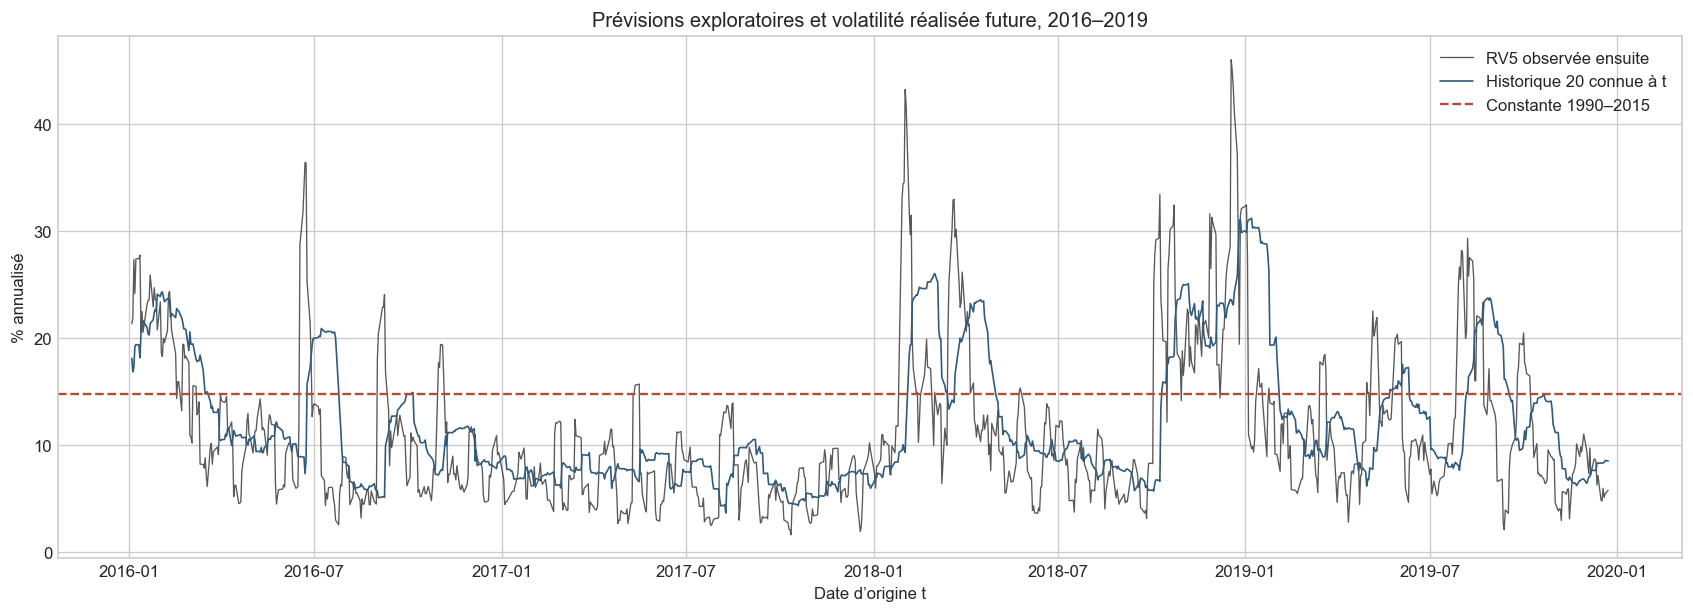

In [7]:
fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
ax.plot(predictions.index, 100 * predictions['rv_5'], label='RV5 observée ensuite', color='#222222', linewidth=0.8, alpha=0.75)
ax.plot(predictions.index, 100 * predictions['prévision_hist_vol_20'], label='Historique 20 connue à t', color='#315b7d', linewidth=1.0)
ax.axhline(100 * constant_forecast, label='Constante 1990–2015', color='#b54a35', linestyle='--', linewidth=1.4)
ax.set(title='Prévisions exploratoires et volatilité réalisée future, 2016–2019', xlabel='Date d’origine t', ylabel='% annualisé')
ax.legend()
plt.show()

 année                prévision   MAE  RMSE  erreur_signée  sous_estimation_pct
  2016  Constante apprentissage 6.541 7.422          3.122               23.016
  2016 Volatilité historique 20 4.681 6.811          1.257               34.524
  2017  Constante apprentissage 8.111 8.640          8.090                1.594
  2017 Volatilité historique 20 2.974 3.565          0.569               35.458
  2018  Constante apprentissage 7.589 9.399         -0.108               38.247
  2018 Volatilité historique 20 5.956 8.357         -0.341               42.629
  2019  Constante apprentissage 5.962 6.782          3.450               21.457
  2019 Volatilité historique 20 5.762 7.478          2.023               34.008


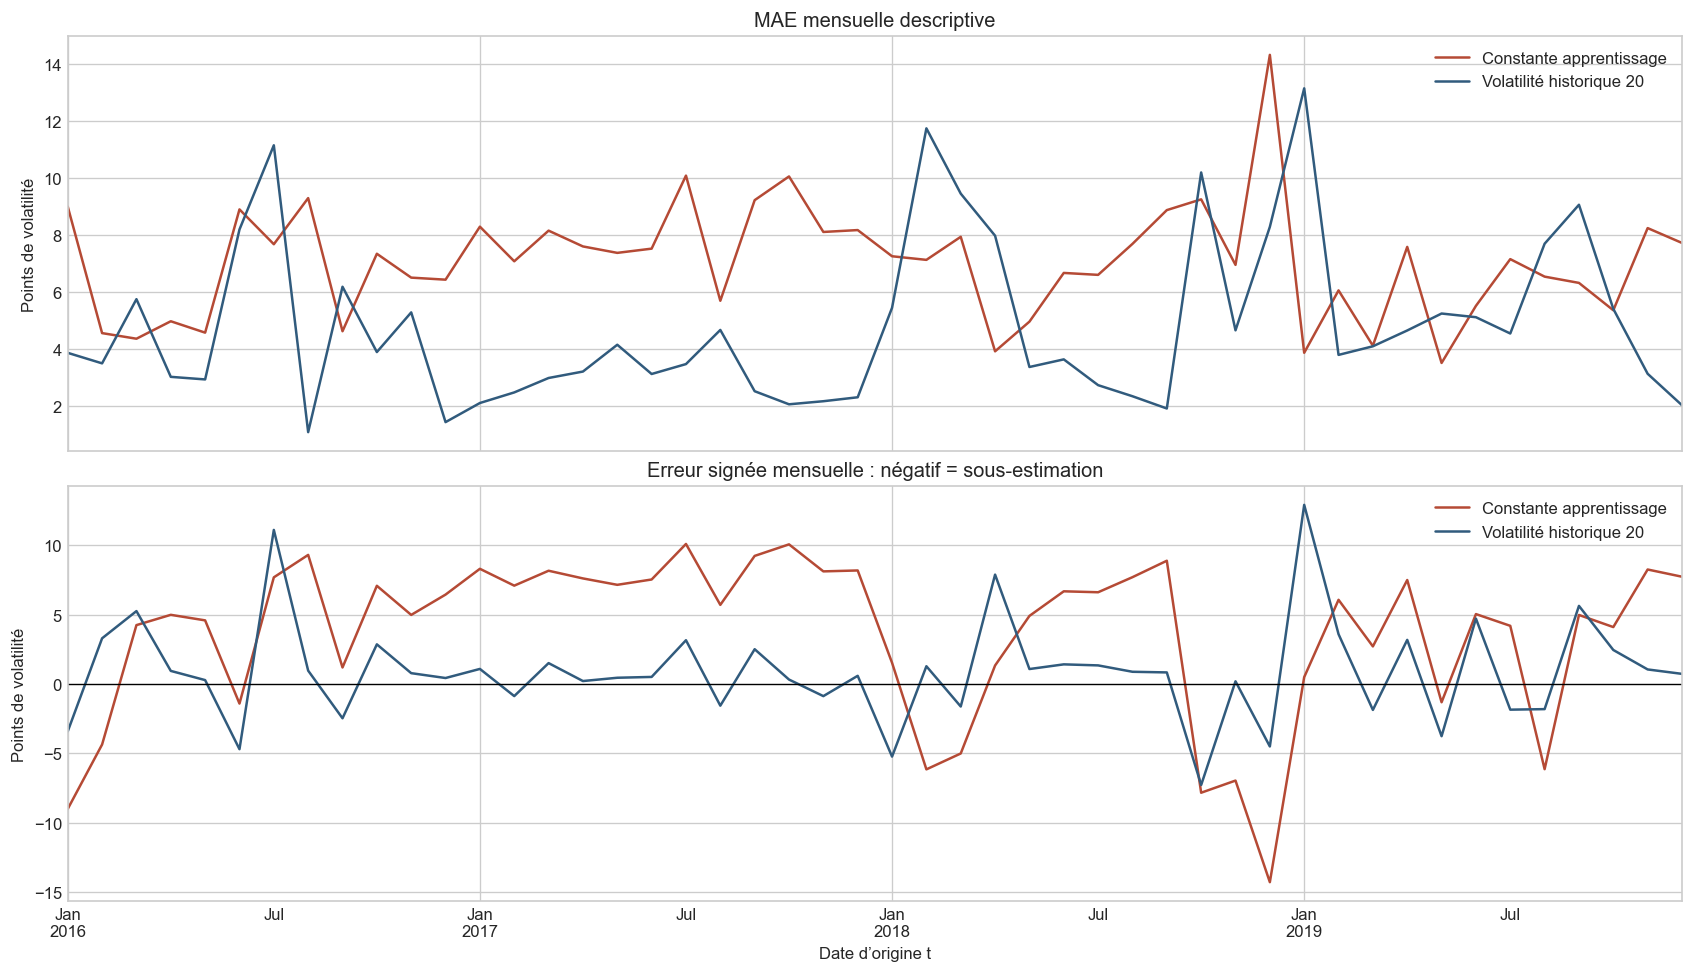

In [8]:
error_frame = pd.DataFrame(index=predictions.index)
for label, column in forecast_columns.items():
    error_frame[(label, 'erreur_signée')] = 100 * (predictions[column] - predictions['rv_5'])
    error_frame[(label, 'erreur_absolue')] = error_frame[(label, 'erreur_signée')].abs()
error_frame.columns = pd.MultiIndex.from_tuples(error_frame.columns)

monthly_mae = error_frame.xs('erreur_absolue', axis=1, level=1).resample('ME').mean()
monthly_bias = error_frame.xs('erreur_signée', axis=1, level=1).resample('ME').mean()
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, constrained_layout=True)
monthly_mae.plot(ax=axes[0], color=['#b54a35', '#315b7d'])
axes[0].set(title='MAE mensuelle descriptive', ylabel='Points de volatilité')
monthly_bias.plot(ax=axes[1], color=['#b54a35', '#315b7d'])
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set(title='Erreur signée mensuelle : négatif = sous-estimation', ylabel='Points de volatilité', xlabel='Date d’origine t')
plt.show()

yearly_rows = []
for year, year_data in predictions.groupby(predictions.index.year):
    for label, column in forecast_columns.items():
        values = descriptive_metrics(year_data['rv_5'], year_data[column])
        yearly_rows.append({
            'année': year,
            'prévision': label,
            'MAE': values['MAE_points_pct'],
            'RMSE': values['RMSE_points_pct'],
            'erreur_signée': values['erreur_signée_moyenne'],
            'sous_estimation_pct': values['fréquence_sous_estimation_pct'],
        })
yearly_metrics = pd.DataFrame(yearly_rows)
print(yearly_metrics.round(3).to_string(index=False))

## 6. Lecture financière simple

Une sous-estimation signifie qu'à la date `t`, le risque annoncé aurait été inférieur à la volatilité ensuite réalisée sur les cinq séances futures. Pour un utilisateur ajustant son exposition au risque prévu, cela pourrait conduire à conserver une exposition trop élevée. Une surestimation pourrait au contraire conduire à une prudence inutile.

Ces conséquences sont seulement des interprétations possibles. Nous n'avons défini ni utilisateur précis, ni règle d'exposition, ni coûts, ni fonction de perte asymétrique. La MAE et la RMSE ne permettent donc pas d'affirmer qu'une prévision produit une meilleure décision financière.

## 7. Interprétation critique

Ce que cette expérience peut établir empiriquement :

- laquelle des deux règles produit les MAE et RMSE les plus faibles sur 2016–2019 ;
- si chaque règle sous-estime ou surestime en moyenne, et à quelle fréquence ;
- si leur avantage descriptif paraît stable ou variable selon les années.

Ce qu'elle ne peut pas établir :

- que l'écart observé est statistiquement robuste, car aucun test n'est réalisé et les cibles se chevauchent ;
- que le résultat se généralise à une autre période, 2016–2019 étant une évaluation exploratoire ;
- que la règle préférable selon MAE/RMSE améliore une décision financière ;
- que la persistance observée a une cause économique déterminée ;
- qu'une méthode plus complexe est nécessaire.

In [9]:
mae_winner = metrics['MAE_points_pct'].idxmin()
rmse_winner = metrics['RMSE_points_pct'].idxmin()
print('OBSERVATIONS EMPIRIQUES SUR 2016–2019 UNIQUEMENT')
print(f'MAE la plus faible : {mae_winner}.')
print(f'RMSE la plus faible : {rmse_winner}.')
for label in metrics.index:
    signed = metrics.loc[label, 'erreur_signée_moyenne']
    direction = 'sous-estimation' if signed < 0 else 'surestimation'
    print(
        f'{label} : {direction} moyenne de {abs(signed):.3f} points ; '
        f'sous-estimation sur {metrics.loc[label, "fréquence_sous_estimation_pct"]:.1f} % des dates.'
    )
mae_winners_by_year = yearly_metrics.loc[yearly_metrics.groupby('année')['MAE'].idxmin(), ['année', 'prévision']]
rmse_winners_by_year = yearly_metrics.loc[yearly_metrics.groupby('année')['RMSE'].idxmin(), ['année', 'prévision']]
print('Prévision à MAE plus faible selon l’année : ' + ', '.join(f'{row.année}: {row.prévision}' for row in mae_winners_by_year.itertuples()))
print('Prévision à RMSE plus faible selon l’année : ' + ', '.join(f'{row.année}: {row.prévision}' for row in rmse_winners_by_year.itertuples()))
print(
    'Lecture financière prudente : la volatilité historique 20 réduit les erreurs moyennes, '
    'mais elle sous-estime plus souvent que la constante sur cette période. Une MAE plus faible '
    'ne suffit donc pas à conclure à une meilleure maîtrise du risque.'
)
print('Conclusion limitée : ces écarts décrivent cette période exploratoire ; ils ne constituent pas une confirmation indépendante.')
print('Aucune extension ne doit être lancée sans accord explicite.')

OBSERVATIONS EMPIRIQUES SUR 2016–2019 UNIQUEMENT
MAE la plus faible : Volatilité historique 20.
RMSE la plus faible : Volatilité historique 20.
Constante apprentissage : surestimation moyenne de 3.639 points ; sous-estimation sur 21.1 % des dates.
Volatilité historique 20 : surestimation moyenne de 0.873 points ; sous-estimation sur 36.7 % des dates.
Prévision à MAE plus faible selon l’année : 2016: Volatilité historique 20, 2017: Volatilité historique 20, 2018: Volatilité historique 20, 2019: Volatilité historique 20
Prévision à RMSE plus faible selon l’année : 2016: Volatilité historique 20, 2017: Volatilité historique 20, 2018: Volatilité historique 20, 2019: Constante apprentissage
Lecture financière prudente : la volatilité historique 20 réduit les erreurs moyennes, mais elle sous-estime plus souvent que la constante sur cette période. Une MAE plus faible ne suffit donc pas à conclure à une meilleure maîtrise du risque.
Conclusion limitée : ces écarts décrivent cette période explo